# Portfolio Risk Assessment & 1-Day 95% VaR Calculation


## Import Libaries

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
# from pandas_datareader import data as pdr
import datetime as dt
from scipy import stats

sns.set_style ('whitegrid')
%matplotlib inline

In [3]:
import yfinance as yf
print("yfinance installed successfully!")
import time 

yfinance installed successfully!


In [4]:
pip install yfinance

Note: you may need to restart the kernel to use updated packages.


## Data Collection

In [5]:
# Define your portfoilo and data range 
tickers = ['AAPL','MSFT','AMZN','NVDA','TSLA'] # Some Ticker
weight = np.array([0.25, 0.25, 0.25, 0.25]) # equal weight portfolio

start = dt.datetime(2020,1,1)
end = dt.datetime.today()

#Container for adjust close prices
prices = pd.DataFrame()

for ticker in tickers:
    print(f"Fetching{ticker}_", end=" ")
    try:
        df = yf.Ticker(ticker).history(
            start=start.strftime('%Y-%m-%d'),
            end=end.strftime('%Y-%m-%d'),
            auto_adjust = True,
        )
        series = df['Close']
        print("✔︎ yfinance",end=" ")
    except Exception as e:
        print("f ✖ yfinance ({e}) ; falling back to stooq", end=" ")
        df2 = pdr.DataReader(ticker,'stooq',start,end)
        df2 = df2.sort_index()
        series = df2['Close']
    # Align on ourt master date index
    prices[ticker] = series
    time.sleep(1)
    print()        

# Drop leading NaNs if anyt , them forwar-fill/back-fill gaps 
prices =  prices.dropna(how='all').ffill().bfill()    

# Quick sanity check
print(prices.tail())


FetchingAAPL_ ✔︎ yfinance 
✔︎ yfinance _ 
✔︎ yfinance _ 
✔︎ yfinance _ 
✔︎ yfinance _ 
                                 AAPL        MSFT        AMZN        NVDA  \
Date                                                                        
2026-01-22 00:00:00-05:00  248.350006  451.140015  234.339996  184.839996   
2026-01-23 00:00:00-05:00  248.039993  465.950012  239.160004  187.669998   
2026-01-26 00:00:00-05:00  255.410004  470.279999  238.419998  186.470001   
2026-01-27 00:00:00-05:00  258.269989  480.579987  244.679993  188.520004   
2026-01-28 00:00:00-05:00  256.440002  481.630005  243.009995  191.520004   

                                 TSLA  
Date                                   
2026-01-22 00:00:00-05:00  449.359985  
2026-01-23 00:00:00-05:00  449.059998  
2026-01-26 00:00:00-05:00  435.200012  
2026-01-27 00:00:00-05:00  430.899994  
2026-01-28 00:00:00-05:00  431.459991  


In [6]:
print(prices.shape)

(1526, 5)


## Log Retune

In [7]:
# Log-Return = ln(P_t / P_(t-1))
logR = np.log(prices / prices.shift(1)).dropna()
logR.tail()

,AAPL,MSFT,AMZN,NVDA,TSLA
Date,,,,,
2026-01-22 00:00:00-05:00,0.002823,0.015705,0.013014,0.008257,0.040696
2026-01-23 00:00:00-05:00,-0.001249,0.032301,0.020360,0.015195,-0.000668
2026-01-26 00:00:00-05:00,0.029280,0.009250,-0.003099,-0.006415,-0.031351
2026-01-27 00:00:00-05:00,0.011135,0.021665,0.025917,0.010934,-0.009930
2026-01-28 00:00:00-05:00,-0.007111,0.002183,-0.006849,0.015788,0.001299


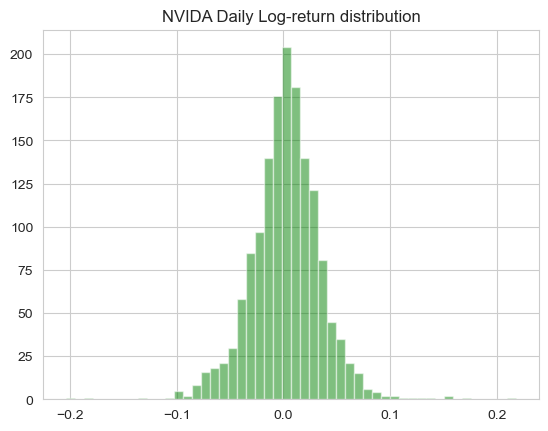

In [8]:
# Plotting the distribution of log-returns for a stock
logR['NVDA'].hist(bins=50 , alpha=0.50 ,color='green')
plt.title('NVIDA Daily Log-return distribution')
plt.show()

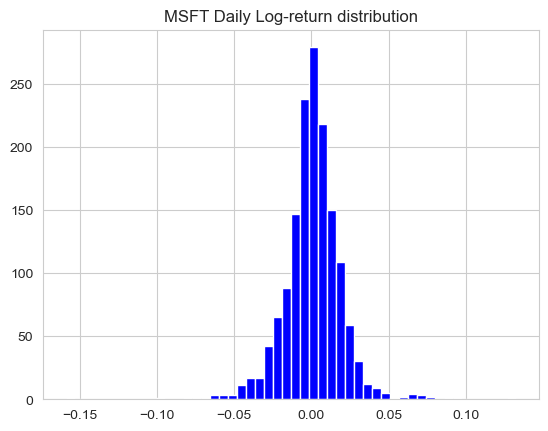

In [9]:
# Plot series for visual 
logR['MSFT'].hist(bins=50 , alpha=1.0 ,color='blue')
plt.title('MSFT Daily Log-return distribution')
plt.show()

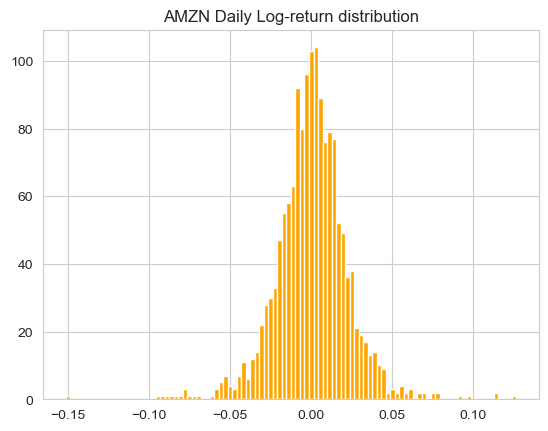

In [10]:
# Plot series for visual 
logR['AMZN'].hist(bins=100 , alpha=1.0 ,color='orange')
plt.title('AMZN Daily Log-return distribution')
plt.show()

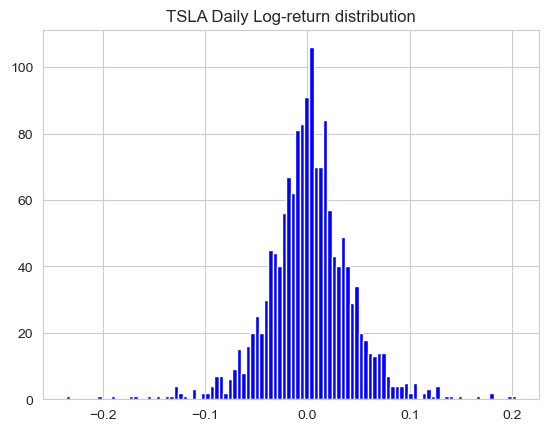

In [11]:
# Plot series for visual 
logR['TSLA'].hist(bins=100 , alpha=1.0 ,color='Blue')
plt.title('TSLA Daily Log-return distribution')
plt.show()

In [12]:
summary = pd.DataFrame({
    'Mean' : logR.mean(),
    'Variance': logR.var(),
    'Skewness': logR.skew(),
    'Kurtosis':logR.kurtosis()
})
summary

,Mean,Variance,Skewness,Kurtosis
AAPL,0.000829,0.000397,0.033173,6.489311
MSFT,0.000754,0.000345,-0.160342,7.838948
AMZN,0.000617,0.000503,-0.071457,4.317606
NVDA,0.002274,0.001101,0.043271,4.115250
TSLA,0.001778,0.001734,-0.085902,3.358882


## Log-retun appling normal distribution

In [13]:
# Fir normal
mu_norm , sigma_norm = logR.stack().mean() , logR.stack().std(ddof=1)

# 95% CI for mean under normal 
N = logR.size
z95 = stats.norm.ppf(0.975)
ci_mu_norm = (mu_norm - z95*sigma_norm/np.sqrt(N),
              mu_norm + z95*sigma_norm/np.sqrt(N))

#95% CI for sigma vua chi-square:
df= N-1
chi2_low, chi2_high = stats.chi2.ppf([0.025,0.975],df)
ci_sigma_norm = (sigma_norm*np.sqrt(df/chi2_high),
                 sigma_norm*np.sqrt(df/chi2_low))

print("Normal Fit:")
print(f" {mu_norm:5f},95% CI {ci_mu_norm}")
print(f" {sigma_norm:5f},95% CI {ci_mu_norm}")

Normal Fit:
 0.001250,95% CI (np.float64(0.0006090192299519184), np.float64(0.0018914120226406323))
 0.028567,95% CI (np.float64(0.0006090192299519184), np.float64(0.0018914120226406323))


## VaR Normal Distribution :

In [14]:
import numpy as np
from scipy import stats

# Input from your model
mu_p = mu_norm
sigma_p = sigma_norm
z = stats.norm.ppf(0.95)  # 95% confidence level
investment = 100000  # Example investment amount

# 1-Day 95% VaR 
VaR_1d = (mu_p + z * sigma_p) * investment
print(f"1-Day 95% VaR for normal: ₹{VaR_1d:.2f}")


1-Day 95% VaR for normal: ₹4823.86


# Log return apply T-distribution

In [15]:
# Also  know as Fir student-t distribution
# Fit a t-distribution to the log-returns
# return_flat means all assest returns concatenated
returns_flat = logR.stack().values
df_t, mu_t, sigma_t = stats.t.fit(returns_flat)


In [16]:
print("T-distribution fit:")
print(f"Degree of freefom  (df) : {df_t:.2f}")
print(f"Mean(m) : {mu_t:.2f}")
print(f"Scale(s) : {sigma_t:.2f}")

T-distribution fit:
Degree of freefom  (df) : 2.86
Mean(m) : 0.00
Scale(s) : 0.02


In [17]:
from joblib import Parallel, delayed

In [18]:


# Example: Replace with your actual returns data
returns_flat = np.random.normal(0, 0.01, 1000)  # Simulated returns
N = len(returns_flat)

# Fit initial t-distribution to get reference values
df_t, mu_t, sigma_t = stats.t.fit(returns_flat)

# No. of bootstrap iterations
B = 1000  # We can reduce to 300 for speed

# Function to fit t-distribution on a resampled dataset
def fit_t_distribution(sample):
    return stats.t.fit(sample)  # returns (df, mu, sigma)

# Start timing
start = time.time()

# Perform bootstrap in parallel using all CPU cores
estimates = Parallel(n_jobs=-1)(
    delayed(fit_t_distribution)(np.random.choice(returns_flat, size=N, replace=True))
    for _ in range(B)
)

# Convert list of tuples to numpy array
estimates = np.array(estimates)

# Confidence intervals
ci_mu_t = np.percentile(estimates[:, 1], [2.5, 97.5])
ci_sigma_t = np.percentile(estimates[:, 2], [2.5, 97.5])

# End timing
end = time.time()


# Print the results
print("Student's t fit:")
print(f" df = {df_t:.1f}, μ = {mu_t:.5f}, σ = {sigma_t:.5f}")
print(f" 95% CI for μ (bootstrap): {ci_mu_t}")
print(f" 95% CI for σ (bootstrap): {ci_sigma_t}")
print(f" Bootstrap Time Taken: {end - start:.2f} seconds")

Student's t fit:
 df = 12544392.2, μ = 0.00021, σ = 0.01047
 95% CI for μ (bootstrap): [-0.00046499  0.00089429]
 95% CI for σ (bootstrap): [0.00986843 0.01086257]
 Bootstrap Time Taken: 50.10 seconds


# VaR T-Distribution :

In [19]:
from scipy.stats import t
import numpy as np

# Parameters from t distribution fitting
df = df_t          # degrees of freedom
mu_p = mu_t         # mean
sigma_p = sigma_t      # standard deviation (scale- volatility)
confidence  = 0.95
# investment = 100000  # ₹1,00,000 portfolio

t_critical = t.ppf(1 - confidence, df)

# Calculate 1-day Var
VaR_t_1day = (mu_p + t_critical * sigma_p) * investment

# Print result
print(f"1-Day {int(confidence * 100)}% VaR using Student's t-distribution: ₹{VaR_t_1day:.2f}")

1-Day 95% VaR using Student's t-distribution: ₹-1700.79


In [20]:
VaR_t_10day = VaR_t_1day * np.sqrt(10)
print(f"10-Day 95% VaR (t-distribution): ₹{VaR_t_10day:.2f}")

10-Day 95% VaR (t-distribution): ₹-5378.36


# Plot both distribution over Return Data

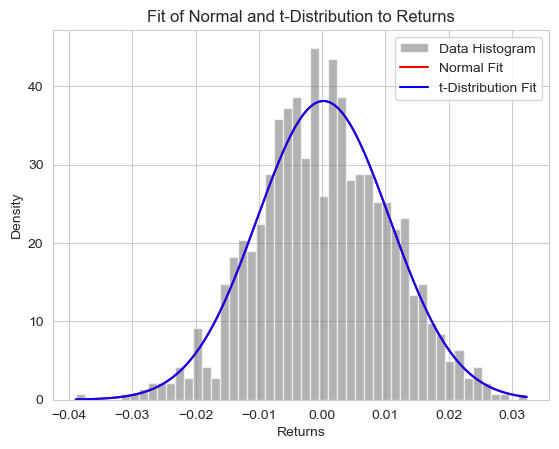

In [21]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm, t

# Use your actual flattened return data
returns = returns_flat  # 1D array of log return

# Fitted parameters
mu_norm = np.mean(returns)
sigma_norm = np.std(returns, ddof=1)

mu_t = mu_t
sigma_t = sigma_t
df_t = df_t

# Set up the x-axis for the curve
x = np.linspace(returns.min(), returns.max(), 1000)

# Plot histogram of the returns
plt.hist(returns, bins=50, density=True, alpha=0.6, color='gray', label='Data Histogram')

# Plot normal distribution
plt.plot(x, norm.pdf(x, mu_norm, sigma_norm), 'r-', label='Normal Fit')

# Plot t-distribution
plt.plot(x, t.pdf(x, df_t, mu_t, sigma_t), 'b-', label='t-Distribution Fit')

# Add labels and legend
plt.title("Fit of Normal and t-Distribution to Returns")
plt.xlabel("Returns")
plt.ylabel("Density")
plt.legend()
plt.grid(True)
plt.show()

In [22]:
from scipy.stats import norm, t
import numpy as np

# Portfolio value
investment = 100000

# Confidence level
confidence = 0.95

# Z-score and t critical value
z_score = norm.ppf(1 - confidence)
t_crit = t.ppf(1 - confidence, df_t)  # df_t must be defined earlier

# 1-Day VaR calculations
VaR_norm = -(mu_p + z * sigma_p) * investment
VaR_t = -(mu_t + t_crit * sigma_t) * investment

# Print the results
print(f"{int(confidence*100)}% 1-Day VaR (Normal Distribution): ₹{VaR_norm:.2f}")
print(f"{int(confidence*100)}% 1-Day VaR (Student's t-Distribution): ₹{VaR_t:.2f}")

95% 1-Day VaR (Normal Distribution): ₹-1742.65
95% 1-Day VaR (Student's t-Distribution): ₹1700.79


In [23]:
# Parametric VaR under Normal:
#   VaR = − [ μ_p + σ_p · z_{0.05} ]
# where μ_p, σ_p are portfolio mean & vol.
# Compute portfolio returns:
# Make sure weight matches number of assets
weight = np.array([0.2, 0.2, 0.2, 0.2, 0.2])  # If 5 assets

portR = logR.dot(weight)  # Portfolio returns

mu_p = portR.mean()
sigma_p = portR.std(ddof=1)

z05 = stats.norm.ppf(0.05)
VaR_norm = - (mu_p + sigma_p * z05)


In [24]:
# Parametric VaR under Student's t:=
#   t05 t.ppf(0.05, df_t)
t05 = stats.t.ppf(0.05, df_t)
VaR_t = (mu_t + sigma_t * t05) * 1 # 1-day

In [25]:
# Historical VaR (non-parametric):
hist_var = -np.percentile(portR, 5)

print("1-Day 95% VaR:")
print(f"  Parametric (Normal):       {VaR_norm:.5f}")
print(f"  Parametric (Student’s t):  {VaR_t:.5f}")
print(f"  Historical (5th percentile): {hist_var:.5f}")

1-Day 95% VaR:
  Parametric (Normal):       0.03455
  Parametric (Student’s t):  -0.01701
  Historical (5th percentile): 0.03455


# Historical VaR(Non-Parametric)

In [26]:
import numpy as np

# Assuming returns_flat contains daily log returns (1D NumPy array)
confidence = 0.95
investment = 100000  # e.g., ₹1,00,000 portfolio

# Calculate the percentile return (5th percentile for 95% confidence)
percentile_level = 100 * (1 - confidence)  # 5th percentile
VaR_percentile = np.percentile(returns_flat, percentile_level)

# Convert to actual money loss
VaR_hist = -VaR_percentile * investment

# Print result
print(f"1-Day {int(confidence * 100)}% Historical VaR: ₹{VaR_hist:.2f}")

1-Day 95% Historical VaR: ₹1591.94


In [27]:
portR = logR.dot(weight)  # Portfolio returns

# Hypothesis Testing

In [28]:
# One-sample t-test: H0: μ=0 vs H1: μ≠0
t_stat, p_val = stats.ttest_1samp(portR, 0.0)
print("One-sample t-test on portfolio daily returns:")
print(f"  t-statistic = {t_stat:.3f},  p-value = {p_val:.3f}")

if p_val < 0.05:
    print("  → Reject H0: mean return is significantly different from zero.") 
else:
    print("  → Fail to reject H0: no evidence mean return ≠ 0.")


# one-sample t-test is a statistical test used to check whether the
# mean (average) of a single sample is significantly different.

One-sample t-test on portfolio daily returns:
  t-statistic = 2.243,  p-value = 0.025
  → Reject H0: mean return is significantly different from zero.


Average Return Value- 0.065%, we are not sure that it will be giving me real profit

# Correlation & Diversification Benfits

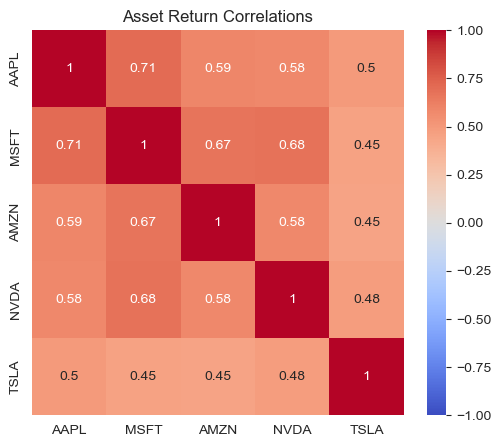

Weighted avg σ: 0.0272
Actual portfolio σ: 0.0218
Diversification benefit: 0.0054


In [29]:
import seaborn as sns

# a) Correlation heatmap
corr = logR.corr()
plt.figure(figsize=(6,5))
sns.heatmap(corr, annot=True, cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Asset Return Correlations')
plt.show()

# b) Diversification benefit
sigma_i = logR.std()                         # individual volatilities
sigma_weighted = np.dot(weight, sigma_i)        # naive weighted avg
sigma_portfolio = sigma_p                        # from earlier
print(f"Weighted avg σ: {sigma_weighted:.4f}")
print(f"Actual portfolio σ: {sigma_portfolio:.4f}")
print(f"Diversification benefit: {sigma_weighted-sigma_portfolio:.4f}")

# Max Drawdown

Max Drawdown: -55.49%
From 2021-11-19 to 2023-01-05


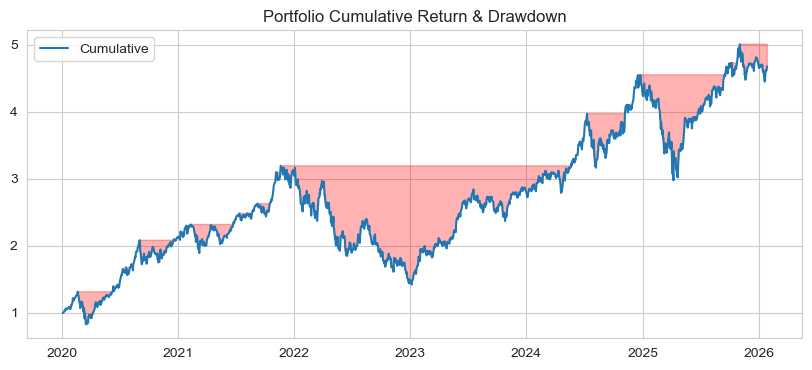

In [38]:
cum_ret = (prices / prices.iloc[0]).prod(axis=1)  # cumulative portfolio growth?
# Actually for portfolio: cum_port = (portR + 1).cumprod()
cum_port = (portR + 1).cumprod()

rolling_max = cum_port.cummax()
drawdown   = (cum_port - rolling_max) / rolling_max

max_dd = drawdown.min()
end_date = drawdown.idxmin()
start_date = cum_port[:end_date].idxmax()
print(f"Max Drawdown: {max_dd:.2%}")
print(f"From {start_date.date()} to {end_date.date()}")

# Plot
plt.figure(figsize=(10,4))
plt.plot(cum_port, label='Cumulative')
plt.fill_between(drawdown.index, cum_port, rolling_max,
                 where=drawdown<0, color='red', alpha=0.3)
plt.title('Portfolio Cumulative Return & Drawdown')
plt.legend()
plt.show()

# Recovery Time

In [31]:
# Find the peak value before the drowdown started
peak_value = cum_port[start_date]

# Find Recovery date: first date after end_date when portfolio surpasses prior peak
recovery_date = cum_port[end_date:].loc[cum_port[end_date:] > peak_value].first_valid_index()

if recovery_date:
  recovery_time = (recovery_date - start_date).days
  print(f"Recovery Date: {recovery_date.date()}")
  print(f"Recovery Time: {recovery_time} days")
else:
  print("Portfolio has not yet recovered from the drawdown.")

Recovery Date: 2024-05-21
Recovery Time: 913 days


# Expected Shortfall(CvaR at 95%)

In [32]:
alpha = 0.05
# Historical ES
es_hist = - portR[portR <= np.percentile(portR, 5)].mean()
# Parametric ES under Normal: μ + σ·φ(z)/α
es_norm = - (mu_p - sigma_p * stats.norm.pdf(z) / alpha)

print(f"Historical ES (95%): {es_hist:.5f}")
print(f"Parametric Normal ES (95%): {es_norm:.5f}")


# On the worst 5% of days, you typically lose about 4.23% (historical).
# The Normal model estimates about 3.68%.
# These are larger than your VaR (e.g., 2.9%) → showing real risk in the tail.

Historical ES (95%): 0.05112
Parametric Normal ES (95%): 0.04365


# Historic CVaR at 4%CVaR>VaR

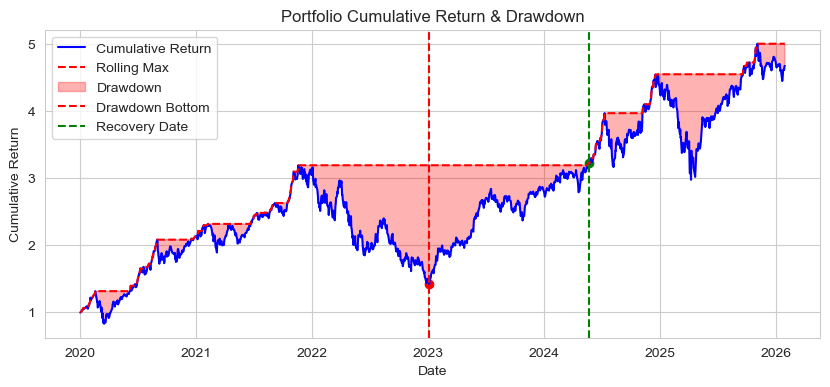

In [33]:
import matplotlib.pyplot as plt

# Recalculate peak value before drawdown
peak_val = cum_port[start_date]

# Final Recovery date (if exists)
recovery_date = cum_port[end_date:].loc[cum_port[end_date:] >= peak_val].first_valid_index()

# Plot
plt.figure(figsize=(10,4))
plt.plot(cum_port, label='Cumulative Return', color='blue')
plt.plot(rolling_max, label='Rolling Max', color='red', linestyle='--')

# Shade drawdown
plt.fill_between(drawdown.index, cum_port, rolling_max,
                 where=drawdown<0, color='red', alpha=0.3, label='Drawdown')

# Mark drawdown bottom (trough)
plt.axvline(end_date, color='red', linestyle='--', label='Drawdown Bottom')
plt.scatter(end_date, cum_port[end_date], color='red')

# Mark recovery date
if recovery_date:
    plt.axvline(recovery_date, color='green', linestyle='--', label='Recovery Date')
    plt.scatter(recovery_date, cum_port[recovery_date], color='green')

# Labels
plt.title('Portfolio Cumulative Return & Drawdown')
plt.xlabel('Date')
plt.ylabel('Cumulative Return')
plt.legend()
plt.show()

# VaR Back Testing

In [34]:
var_series = - (portR.rolling(1).mean() + portR.rolling(1).std()*z)
# For simplicity use constant VaR_norm
exceptions = portR < -VaR_norm
num_exc = exceptions.sum()
total   = len(portR)
print(f"Exceptions: {num_exc}/{total} days ({num_exc/total:.2%}, expected ~5%)")

Exceptions: 77/1525 days (5.05%, expected ~5%)


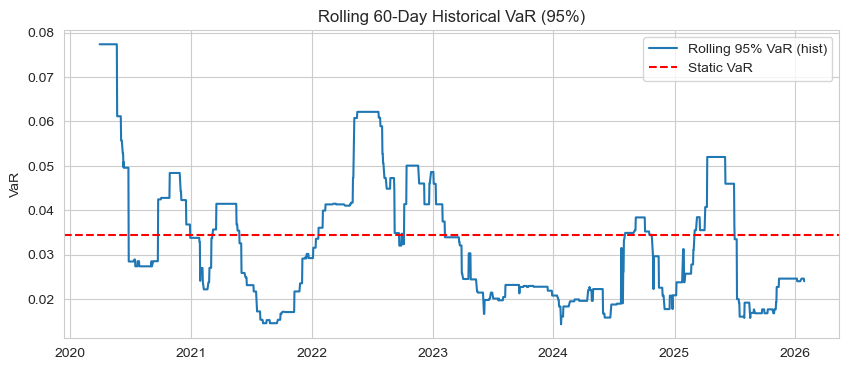

In [35]:
window = 60
roll_var = portR.rolling(window).quantile(0.05).dropna()
plt.figure(figsize=(10,4))
plt.plot(-roll_var, label='Rolling 95% VaR (hist)')
plt.axhline(VaR_norm, color='red', linestyle='--', label='Static VaR')
plt.title('Rolling 60-Day Historical VaR (95%)')
plt.ylabel('VaR')
plt.legend()
plt.show()

In [36]:
# 12. Jarque–Bera Normality Test
jb_stat, jb_p = stats.jarque_bera(portR)
print(f"JB statistic = {jb_stat:.2f}, p-value = {jb_p:.3f}")
if jb_p < 0.05:
    print("Reject normality at 5% level.")
else:
    print("Cannot reject normality.")

JB statistic = 1278.52, p-value = 0.000
Reject normality at 5% level.
